# Computational Scalability and Query Cost Analysis

**Framework:** ESCI (Energy-Guided Sentence-Level Counterfactual Interpreter)  
**Baseline:** LIME (Local Interpretable Model-agnostic Explanations)  
**Context:** Sharif University of Technology — M.Sc. Thesis (Chapter 5)  

---

### Overview
This notebook provides a clean, academic, and standard evaluation of computational scalability and target LLM query consumption between:
1. **Perturbation Baseline (LIME):** Combinatorial perturbation sampling $\mathcal{O}(2^N)$ capped at $K_{\text{max}} = 1000$ queries per audited prompt.
2. **Amortized Interpreter (ESCI):** Offline pre-training cost ($D_{\text{train}} = 20,000$ queries) amortized over all subsequent inferences, requiring **0** additional target model queries at test time (constant $\mathcal{O}(1)$ forward-pass inference).

Executing this notebook generates the publication figure: `figures/Fig-INTERP-Computational-Scalability-V3.pdf`.

In [1]:
import os
import tempfile
from pathlib import Path

# Configure Matplotlib cache directory to ensure clean execution across environments
os.environ["MPLCONFIGDIR"] = os.path.join(tempfile.gettempdir(), "matplotlib")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import scienceplots

# Configure publication-grade styling
plt.style.use(["science"])
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "serif"],
    "text.usetex": False,
    "figure.figsize": [8.0, 3.1],
    "figure.dpi": 300,
    "axes.labelsize": 9.5,
    "axes.titlesize": 10.0,
    "xtick.labelsize": 9.0,
    "ytick.labelsize": 9.0,
    "legend.fontsize": 8.5,
    "lines.linewidth": 2.0,
    "savefig.pad_inches": 0.08,
})

print("Environment and publication styling configured successfully.")

Environment and publication styling configured successfully.


## Analytical Cost Model & Derivations

As detailed in Chapter 5 of the thesis:

### 1. Perturbation Overhead in LIME
For a target prompt with $N$ sentences, evaluating combinatorial subsets entails exponential complexity $\mathcal{O}(2^N)$. In our benchmark datasets, the mean prompt length is $N = 15$ sentences ($2^{15} = 32,768$ states). To maintain tractability, black-box LIME caps perturbations at $K_{\text{max}} = 1000$:

$$\text{Cost}_{\text{LIME}} = \min(2^N, 1000) \implies \text{Cost}_{\text{LIME\_Avg}} = \min(2^{15}, 1000) = 1,000 \text{ queries/prompt}$$

### 2. Upfront Pre-training Amortization in ESCI
In contrast, ESCI shifts the computational workload to an offline pre-training stage with $D_{\text{train}} = 20,000$ queries to train the surrogate and energy network. Once trained, extracting explanations requires **0** additional queries to the target LLM (constant $\mathcal{O}(1)$ forward pass).

### 3. Break-Even Analysis
The computational break-even point $N_{\text{break-even}}$ between ESCI and LIME is reached when:

$$N_{\text{break-even}} = \frac{D_{\text{train}}}{K_{\text{LIME\_Avg}}} = \frac{20,000}{1,000} = 20 \text{ prompts}$$

Hence, after auditing just $20$ average-length prompts, ESCI fully amortizes its initial pre-training cost.

In [2]:
# ==========================================================
# Model and Computational Parameters
# ==========================================================
esci_training_queries = 20000   # D_train: offline pre-training queries
esci_inference_queries = 0      # K_ESCI: target LLM queries per prompt at inference
lime_inference_queries = 1000   # K_LIME_Avg: target LLM queries per prompt

# Compute break-even point
break_even_prompts = int(esci_training_queries / lime_inference_queries)
break_even_queries = esci_training_queries

# Prompts range for cumulative evaluation
x_max = 100
prompts = np.linspace(0, x_max, 500)

# Cumulative trajectories
lime_cumulative = prompts * lime_inference_queries
esci_cumulative = np.full_like(prompts, esci_training_queries)

print(f"Break-even Point: {break_even_prompts} prompts ({break_even_queries:,} queries)")
print(f"ESCI Pre-training Cost: {esci_training_queries:,} queries")
print(f"ESCI Test-time Cost per Prompt: {esci_inference_queries} queries")
print(f"LIME Test-time Cost per Prompt: {lime_inference_queries:,} queries")

Break-even Point: 20 prompts (20,000 queries)
ESCI Pre-training Cost: 20,000 queries
ESCI Test-time Cost per Prompt: 0 queries
LIME Test-time Cost per Prompt: 1,000 queries


## Publication-Ready Visualization (1×2 Subplot)

The visualization is designed with academic publishing standards:
- **Left Panel:** Displays cumulative query cost (Training + Inference) to showcase the amortization curve, break-even point, and ESCI net query savings.
- **Right Panel:** Displays the per-prompt marginal cost at inference time ($1,000$ vs $0$).

Successfully exported PDF figure to: figures/Fig-INTERP-Computational-Scalability-V3.pdf
Successfully exported PNG preview figure to: figures/Fig-INTERP-Computational-Scalability-V3.png


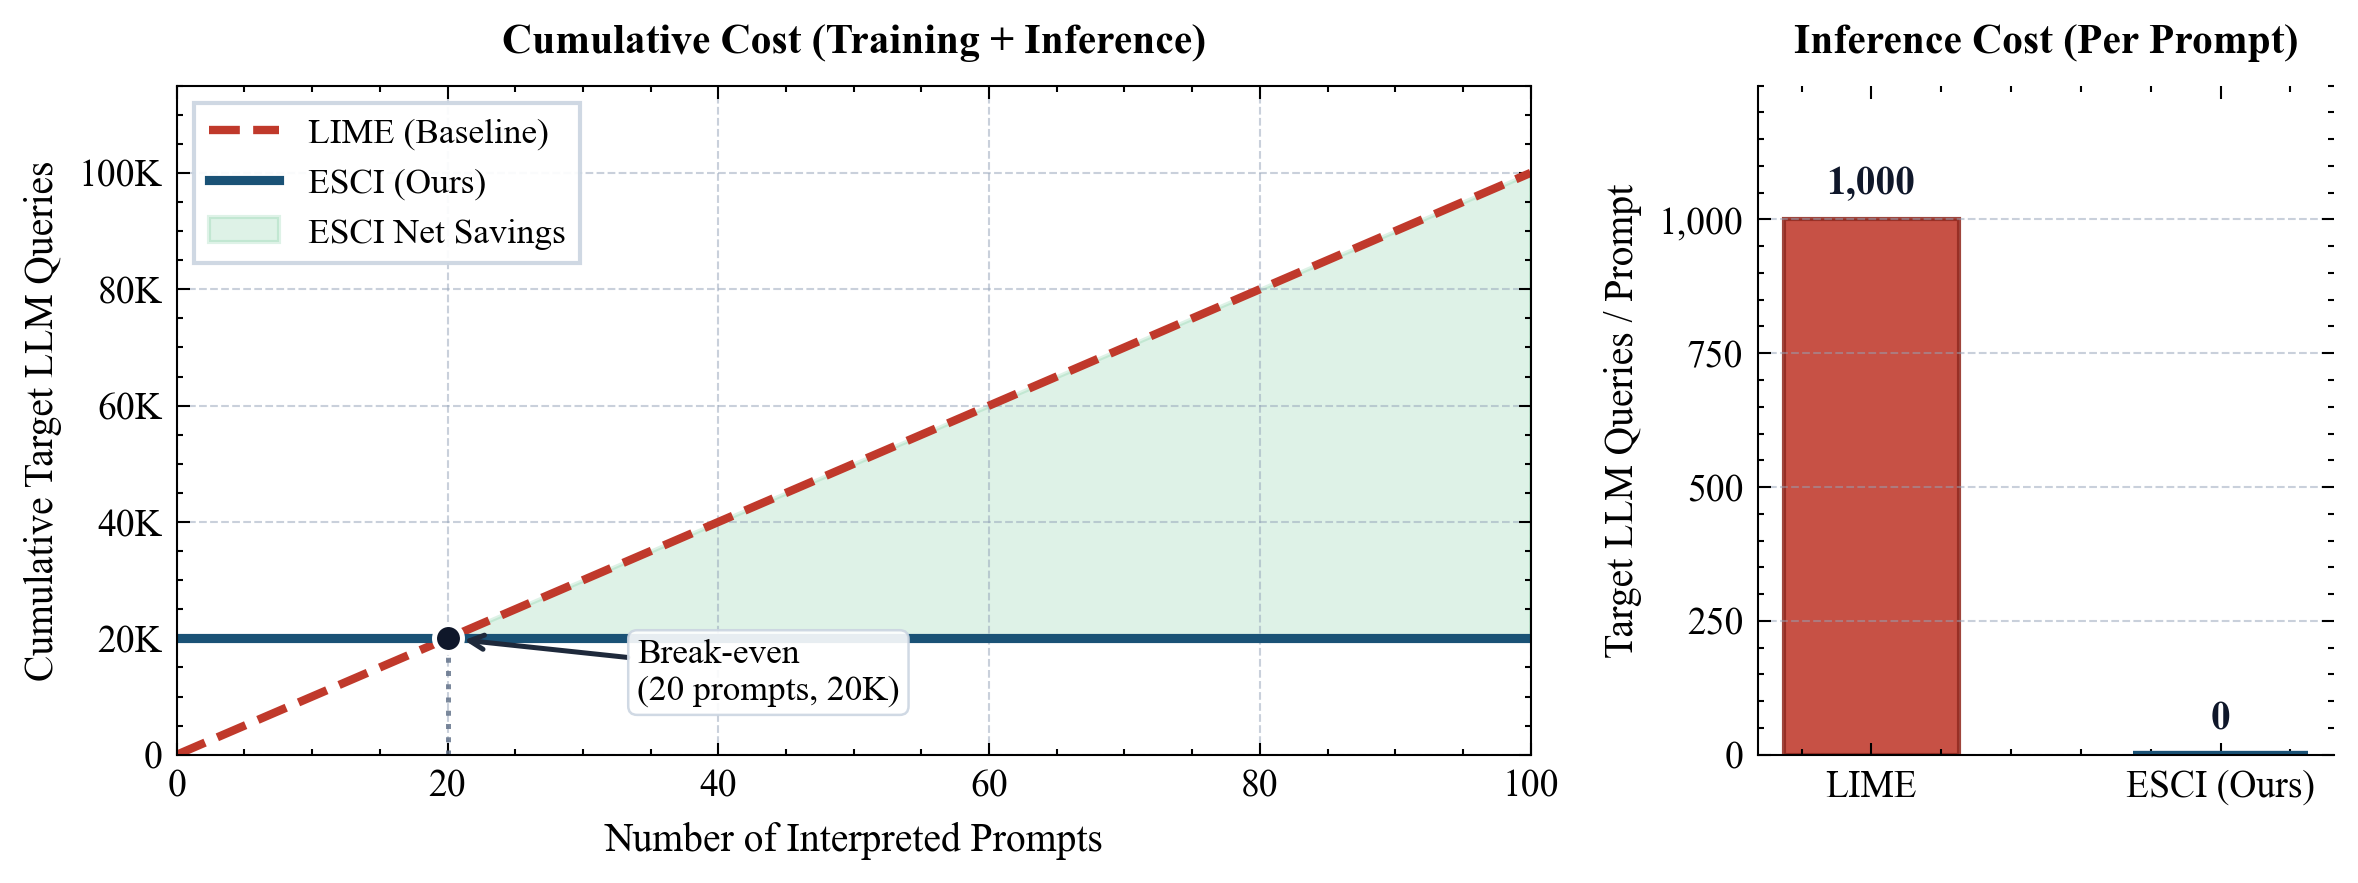

In [3]:
# Output paths
fig_dir = Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)
output_pdf = fig_dir / "Fig-INTERP-Computational-Scalability-V3.pdf"
output_png = fig_dir / "Fig-INTERP-Computational-Scalability-V3.png"

# Refined Academic Color Palette
color_lime = "#C0392B"     # Refined Academic Crimson
color_esci = "#1A5276"     # Refined Academic Navy Blue
color_savings = "#27AE60"  # Academic Emerald Green
color_grid = "#94A3B8"     # Subtle Slate Grid

# Create 1x2 subplot layout with customized width ratio
fig, (ax1, ax2) = plt.subplots(
    1, 2, gridspec_kw={"width_ratios": [2.35, 1]}, figsize=(8.0, 3.1)
)

# =========================================================
# LEFT PANEL: Cumulative Queries (Training + Inference)
# =========================================================
ax1.plot(
    prompts,
    lime_cumulative,
    label="LIME (Baseline)",
    color=color_lime,
    linestyle="--",
    linewidth=2.0,
)
ax1.plot(
    prompts,
    esci_cumulative,
    label="ESCI (Ours)",
    color=color_esci,
    linestyle="-",
    linewidth=2.2,
)

# Mark and annotate Break-Even Point
y_max = 115000
ax1.scatter(
    [break_even_prompts],
    [break_even_queries],
    color="#0F172A",
    s=45,
    zorder=6,
    edgecolors="white",
    linewidth=1.2,
)
ax1.axvline(
    x=break_even_prompts,
    ymin=0,
    ymax=break_even_queries / y_max,
    color="#64748B",
    linestyle=":",
    alpha=0.85,
    linewidth=1.2,
)
ax1.annotate(
    f"Break-even\n({break_even_prompts} prompts, 20K)",
    xy=(break_even_prompts, break_even_queries),
    xytext=(break_even_prompts + 14, break_even_queries - y_max * 0.09),
    arrowprops=dict(
        arrowstyle="->", color="#1E293B", lw=1.2, shrinkA=0, shrinkB=4
    ),
    fontsize=8.5,
    fontweight="medium",
    bbox=dict(
        boxstyle="round,pad=0.25",
        facecolor="white",
        alpha=0.9,
        edgecolor="#CBD5E1",
        linewidth=0.6,
    ),
)

# Shaded Area: Cumulative ESCI Savings
ax1.fill_between(
    prompts,
    lime_cumulative,
    esci_cumulative,
    where=(lime_cumulative >= esci_cumulative),
    interpolate=True,
    color=color_savings,
    alpha=0.15,
    label="ESCI Net Savings",
)

# Left Panel Labels and Styling
ax1.set_title(
    "Cumulative Cost (Training + Inference)",
    fontsize=10.0,
    pad=8,
    fontweight="bold",
)
ax1.set_xlabel("Number of Interpreted Prompts", fontsize=9.5)
ax1.set_ylabel("Cumulative Target LLM Queries", fontsize=9.5)
ax1.set_xlim(0, x_max)
ax1.set_ylim(0, y_max)
ax1.set_xticks([0, 20, 40, 60, 80, 100])
ax1.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, loc: f"{int(x/1000):,}K" if x > 0 else "0")
)
ax1.legend(
    loc="upper left",
    frameon=True,
    framealpha=0.92,
    edgecolor="#CBD5E1",
    fancybox=False,
    fontsize=8.5,
)
ax1.grid(True, linestyle="--", alpha=0.5, color=color_grid)

# =========================================================
# RIGHT PANEL: Per-Prompt Marginal Cost (Inference Only)
# =========================================================
labels = ["LIME", "ESCI (Ours)"]
values = [lime_inference_queries, esci_inference_queries]
bars = ax2.bar(
    labels,
    values,
    color=[color_lime, color_esci],
    alpha=0.88,
    width=0.5,
    edgecolor=["#922B21", "#154360"],
    linewidth=1.0,
)

# Annotate Bar Heights
for bar in bars:
    h = bar.get_height()
    ax2.annotate(
        f"{int(h):,}",
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color="#0F172A",
    )

# Base indicator for ESCI at y=0
ax2.hlines(
    0,
    bars[1].get_x(),
    bars[1].get_x() + bars[1].get_width(),
    colors=color_esci,
    linewidth=2.0,
)

# Right Panel Labels and Styling
ax2.set_title(
    "Inference Cost (Per Prompt)", fontsize=10.0, pad=8, fontweight="bold"
)
ax2.set_ylabel("Target LLM Queries / Prompt", fontsize=9.5)
ax2.set_ylim(0, 1250)
ax2.set_yticks([0, 250, 500, 750, 1000])
ax2.yaxis.set_major_formatter(
    ticker.FuncFormatter(lambda y, loc: f"{int(y):,}")
)
ax2.grid(axis="y", linestyle="--", alpha=0.5, color=color_grid)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

# Layout adjustments
plt.tight_layout()
plt.subplots_adjust(top=0.88)

# Save high-resolution figures
plt.savefig(output_pdf, format="pdf", bbox_inches="tight", pad_inches=0.08)
plt.savefig(output_png, format="png", dpi=300, bbox_inches="tight", pad_inches=0.08)
print(f"Successfully exported PDF figure to: {output_pdf}")
print(f"Successfully exported PNG preview figure to: {output_png}")
plt.show()

## Summary of Findings

| Metric | LIME (Baseline) | ESCI (Ours) | Difference / Savings |
| :--- | :--- | :--- | :--- |
| **Offline Pre-training Queries** | $0$ | $20,000$ | Upfront one-time investment |
| **Inference Queries per Prompt** | $1,000$ | $0$ | **$100\%$ reduction at inference** ($\mathcal{O}(1)$ forward pass) |
| **Break-Even Prompt Threshold** | — | **$20$ prompts** | Fast amortization of training overhead |
| **Cumulative Queries @ 100 Prompts** | $100,000$ | $20,000$ | **$80,000$ queries saved ($80\%$ reduction)** |
| **Cumulative Queries @ 1,000 Prompts** | $1,000,000$ | $20,000$ | **$980,000$ queries saved ($98\%$ reduction)** |